In [456]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [457]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [458]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Data/processed/concatenated_data_forth_trace.csv',dtype={"value": "float64"})

In [459]:
data.head()

,subject_id,device_id,accelerometer_x,accelerometer_y,accelerometer_z,gyroscope_x,gyroscope_y,gyroscope_z,magnetometer_x,magnetometer_y,magnetometer_z,timestamp,activity_label
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1


In [460]:
final_columns = [
        "pessoa_x",
        "id_dispositivo",
        "acelerômetro_x",
        "acelerômetro_Y",
        "acelerômetro_Z",
        "giroscópio_x",
        "giroscópio_Y",
        "giroscópio_Z",
        "magnetrômetro_x",
        "magnetrômetro_y",
        "magnetrômetro_z",
        "timestamp",
        "atividade"
    ]

In [461]:
data.columns = final_columns

In [462]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1


In [463]:
data.isnull().sum()

pessoa_x           0
id_dispositivo     0
acelerômetro_x     0
acelerômetro_Y     0
acelerômetro_Z     0
giroscópio_x       0
giroscópio_Y       0
giroscópio_Z       0
magnetrômetro_x    0
magnetrômetro_y    0
magnetrômetro_z    0
timestamp          0
atividade          0
dtype: int64

In [464]:
data.shape

(3930873, 13)

In [465]:
#remove the null class
data=data.dropna()

In [466]:
data.shape

(3930873, 13)

In [467]:
data["atividade"].value_counts().sort_index()

atividade
1     805541
2     421504
3     418688
4     699414
5     703766
6     446411
7     223179
8      30976
9      28032
10     29952
11     28160
12     19050
13     38100
14     19050
15      9525
16      9525
Name: count, dtype: int64

In [468]:
data["pessoa_x"].value_counts().sort_index()

pessoa_x
0     265344
1     265216
2     266240
3     266240
4     248704
5     263805
6     267263
7     262397
8     254464
9     260480
10    260864
11    251008
12    265600
13    267008
14    266240
Name: count, dtype: int64

# **Data Exploration**

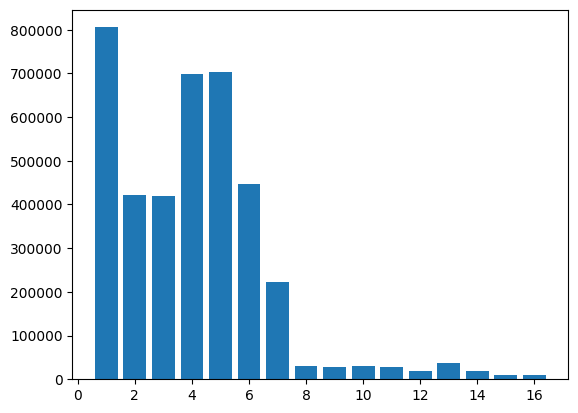

In [469]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

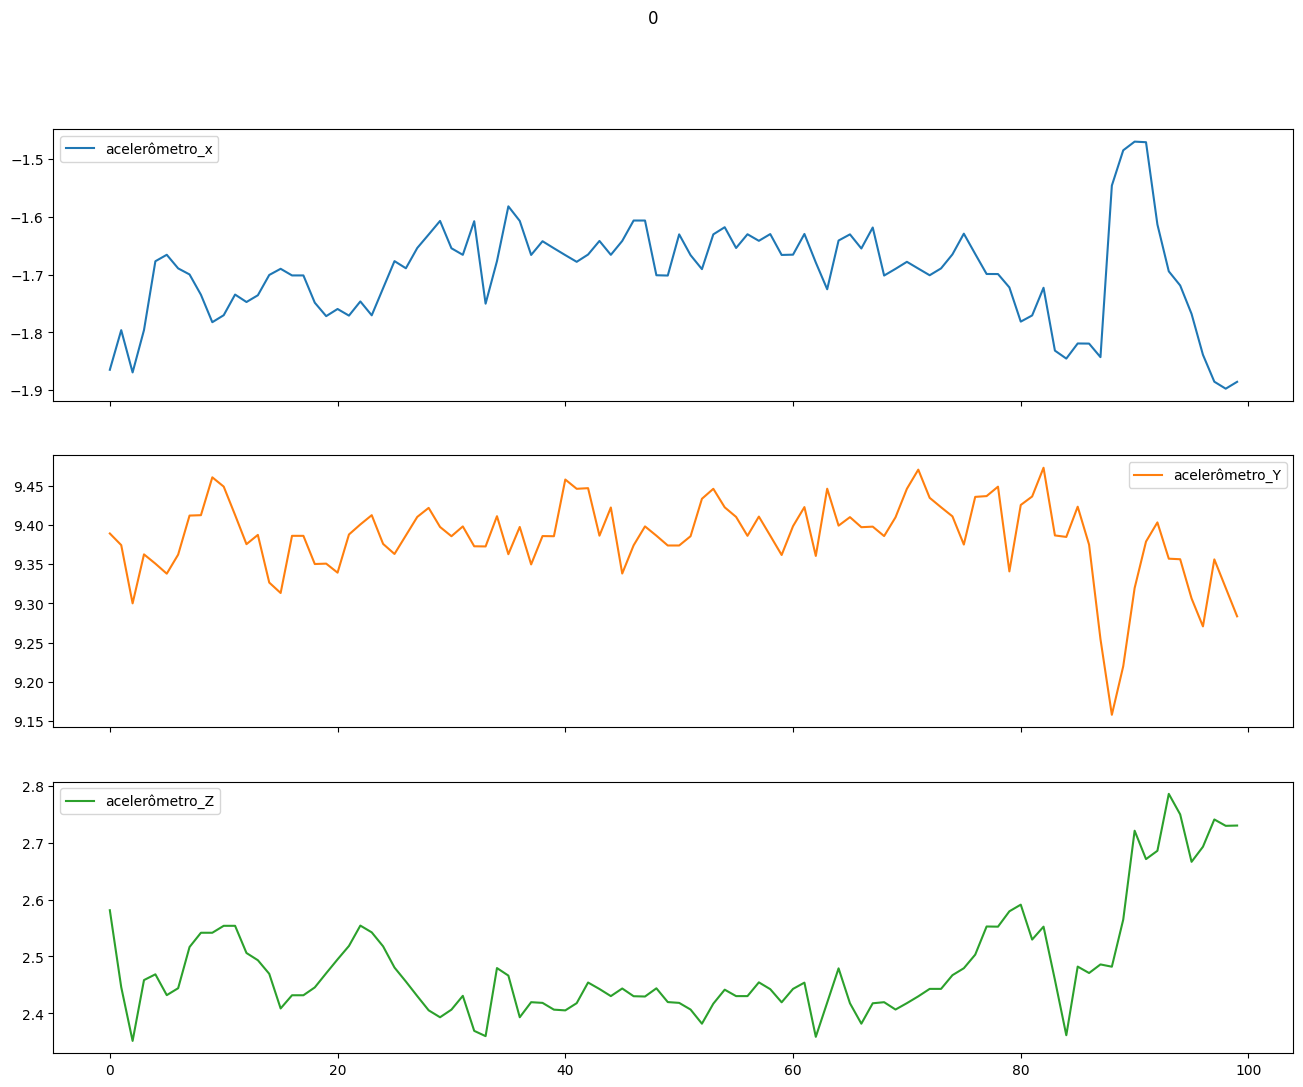

In [470]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:100].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

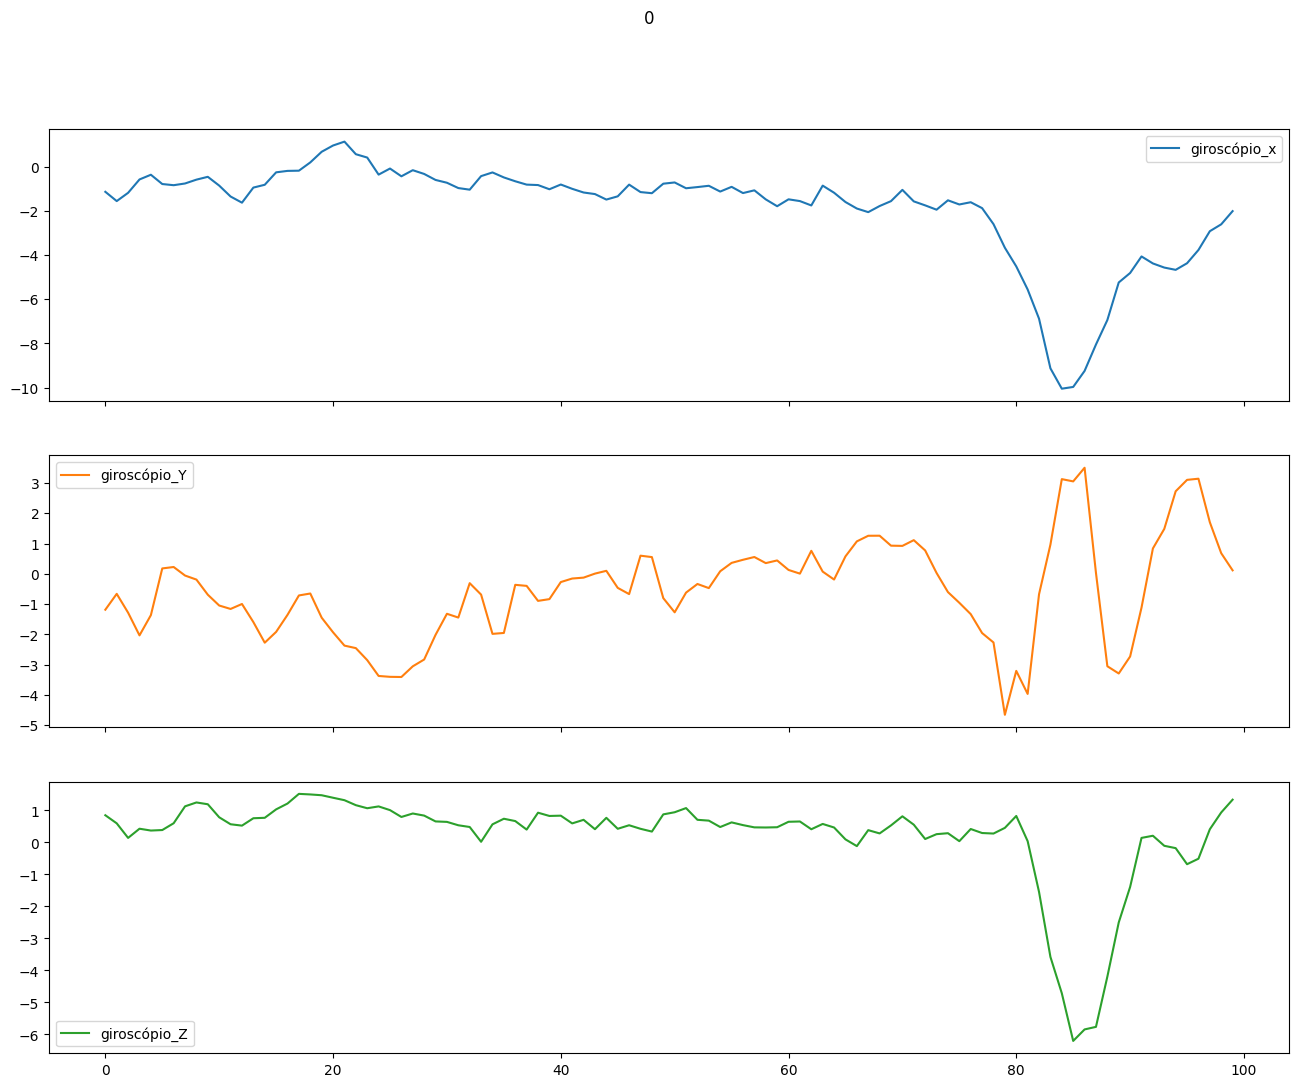

In [471]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:100].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

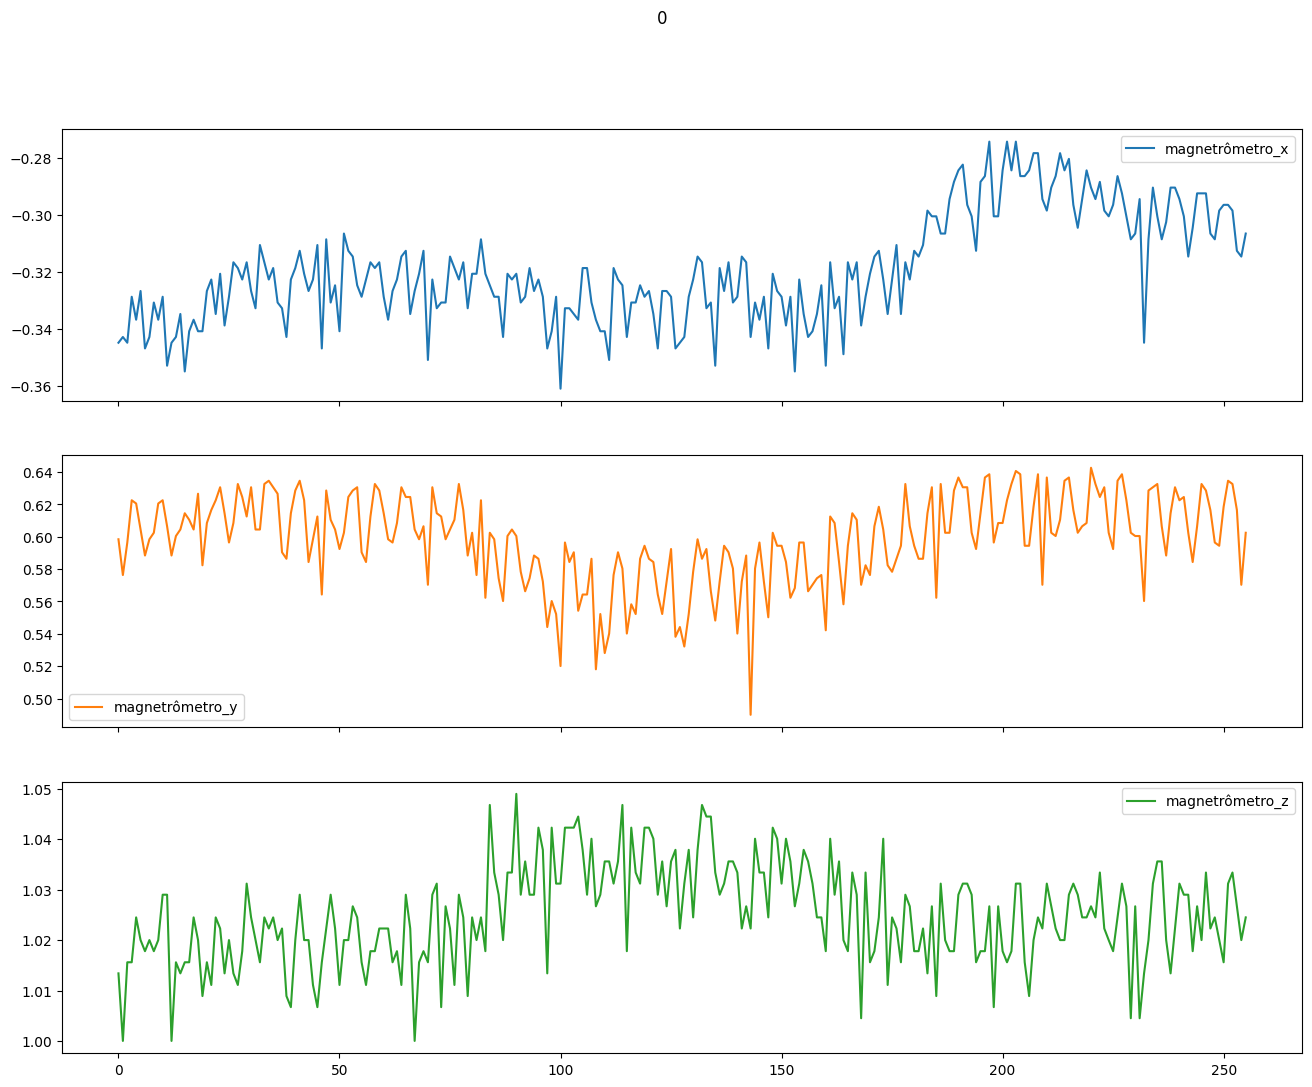

In [472]:
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][:256].plot(title='0',subplots=True, figsize=(16, 12))

In [473]:
data.pessoa_x.unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
      dtype=int64)

In [474]:
data = data.reset_index(drop=True)

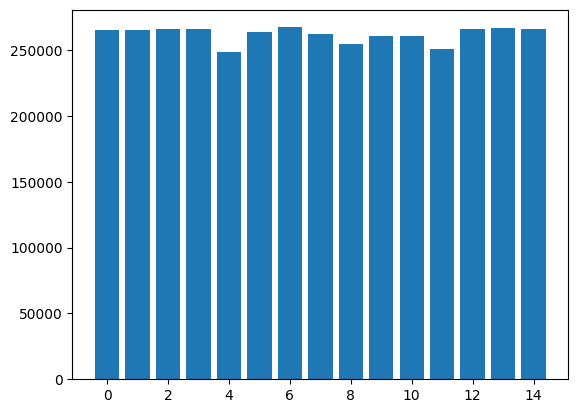

In [475]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [476]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([1,2,4,8,9,12,13])]

In [477]:
# Define the mapping dictionary
mapping_dict = {1:0,2:1,4:2,8:3,9:4,12:5,13:6}

In [478]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [480]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [481]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [482]:
data.shape

(2042617, 13)

In [483]:
grouped_data = data.groupby(['pessoa_x','id_dispositivo'])['atividade'].value_counts().unstack()

In [484]:
print(grouped_data)

atividade                    0     1     2    3    4    5    6
pessoa_x id_dispositivo                                       
0        1               11012  5760  9090  384  384  254  508
         2               11012  5760  8706  384  384  254  508
         3               11012  5760  8962  384  384  254  508
         4               10884  5760  9090  384  384  254  508
         5               10756  5760  9218  384  384  254  508
...                        ...   ...   ...  ...  ...  ...  ...
14       1               10884  5760  9346  256  512  254  508
         2                9988  5632  9474  512  512  254  508
         3               10500  5888  9346  384  384  254  508
         4               10884  5888  9474  256  256  254  508
         5               11012  5760  9346  256  384  254  508

[75 rows x 7 columns]


In [485]:
import pandas as pd

# Example function to organize data by blocks of 'atividade'
def organize_blocks_by_atividade(data):
    """
    Organizes the dataframe by extracting blocks of the same 'atividade' for each 'pessoa_x'.
    Blocks are concatenated vertically for each 'atividade' value in descending order.

    Args:
        data (pd.DataFrame): Input dataframe with columns including 'pessoa_x', 'atividade', and others.

    Returns:
        pd.DataFrame: New dataframe organized by 'atividade' blocks.
    """
    organized_data = pd.DataFrame(columns=data.columns)  # Create an empty DataFrame with the same columns

    # Loop through each pessoa_x
    for pessoa_id, pessoa_data in data.groupby('pessoa_x'):
        # Loop through atividade values from 5 to 0
        for atividade_val in range(6, -1, -1):
            # Get blocks of data for the current 'atividade'
            atividade_block = pessoa_data[pessoa_data['atividade'] == atividade_val]
            # Append to the organized_data
            organized_data = pd.concat([organized_data, atividade_block], axis=0)

    # Reset the index to maintain sequential indexing in the new dataframe
    organized_data.reset_index(drop=True, inplace=True)

    return organized_data

# Assuming 'data' is already loaded as a DataFrame
# organized_data = organize_blocks_by_atividade(data)



In [486]:
data = organize_blocks_by_atividade(data)

In [487]:
data.head(270)

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-2.7696,9.0880,2.5931,-2.6312,3.86680,-0.37698,-0.72984,0.44980,0.62806,473010.0,6
1,0,1,-2.8407,9.0521,2.6075,-2.3104,1.66920,-0.59922,-0.72177,0.45984,0.61693,473030.0,6
2,0,1,-2.7329,9.0890,2.6412,-1.5447,0.28555,-0.22617,-0.71774,0.47189,0.62806,473040.0,6
3,0,1,-2.6856,9.1730,2.6263,-1.5439,0.63277,-0.38040,-0.71371,0.49398,0.62138,473060.0,6
4,0,1,-2.6157,9.2317,2.5506,-2.0485,3.11600,-0.22590,-0.71573,0.49598,0.63029,473080.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,0,1,-2.1982,9.2566,2.5905,2.3542,-1.30690,1.90220,-0.52419,0.58835,0.58352,833220.0,6
266,0,1,-2.1974,9.2092,2.6281,2.4270,-1.98640,2.11570,-0.48790,0.61044,0.59911,833240.0,6
267,0,1,-2.1394,9.0993,2.5559,1.2492,-2.77400,1.86770,-0.49194,0.65060,0.59911,833260.0,6
268,0,1,-2.1882,9.0981,2.4959,1.3770,-2.97190,1.65960,-0.48589,0.64458,0.61693,833280.0,6


In [488]:
grouped_data_organized = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [489]:
print(grouped_data_organized)

atividade      0      1      2     3     4     5     6
pessoa_x                                              
0          54676  28800  45066  1920  1920  1270  2540
1          52628  28288  48266  2176  1920  1270  2540
2          55956  28416  46346  2048  2048  1270  2540
3          54676  29056  46730  2176  1792  1270  2540
4          51220  26240  44298  2304  1920  1270  2540
5          52369  27904  47114  2176  1920  1270  2540
6          58643  28800  47626  1920  1792  1270  2540
7          50705  28928  46858  1920  1792  1270  2540
8          49940  25600  46858  1792  1792  1270  2540
9          51348  28032  47754  2432  1920  1270  2540
10         57876  28416  46858  2176  1664  1270  2540
11         53652  27136  43530  1920  1664  1270  2540
12         53908  28544  48522  2048  1920  1270  2540
13         54676  28416  46602  2304  1920  1270  2540
14         53268  28928  46986  1664  2048  1270  2540


In [490]:
nan_values = grouped_data[grouped_data.isnull().any(axis=1)].index

In [491]:
nan_values_array = nan_values.to_numpy()

In [492]:
print(nan_values)

MultiIndex([], names=['pessoa_x', 'id_dispositivo'])


In [493]:
#data = data[~data['pessoa_x'].isin([1616, 1618, 1637, 1638, 1640, 1642])]

In [494]:
#grouped_data2 = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [495]:
#print(grouped_data2)

# **Models**

In [496]:
def split_and_shuffle_3d_arrays(array_data, labels_data):
    
    combined = list(zip(array_data, labels_data))


    # Step 2: Separate into four parts based on label value
    # Filtering combined list by labels in each window
    grouped_data = {
        i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(3)
    }

    # Step 3: Interlace half of label=1 into half of label=0
    first_third_0 = len(grouped_data[0]) // 3
    half_1 = len(grouped_data[1]) // 3
    interlaced_0 = []

    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:
            interlaced_0.append(grouped_data[1][i])

    # Step 4: Interlace half of label=3 into half of label=2
    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    interlaced_2 = []

    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            interlaced_2.append(grouped_data[3][i])

    # Step 5: Interlace last half of label=0 into last half of label=3
    last_half_1 = grouped_data[1][half_1:]
    last_half_0 = grouped_data[0][half_0:]
    interlaced_1 = []

    for i in range(len(last_half_1)):
        interlaced_1.append(last_half_1[i])
        if i < len(last_half_0):
            interlaced_1.append(last_half_0[i])

    # Step 6: Concatenate the three resulting arrays vertically
    combined_result = interlaced_0 + interlaced_2 + interlaced_3

    # Step 7: Unzip the resulting array into separate data and labels
    data_result, labels_result = zip(*combined_result)

    # Converting back to numpy arrays for further processing if needed
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    return data_result,labels_result



In [497]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [498]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [499]:
""" import numpy as np

# Function to count occurrences of each category
def count_categories(data):
    counts = {
        '[1, 0, 0, 0]': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),
        '[0, 1, 0, 0]': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),
        '[0, 0, 1, 0]': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),
        '[0, 0, 0, 1]': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),
    }
    return counts

# Count categories before removal
print("Category counts before removal:", count_categories(labels_data_categorical))

# Define the desired class count for the first category
desired_class_count = 2151

# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical
first_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]

# Randomly select indices to remove to balance the first class
indices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_count), replace=False)

# Remove the selected indices from both labels_data_categorical and segments_data
labels_data_categorical = np.delete(labels_data_categorical, indices_to_remove, axis=0)
segments_data = np.delete(segments_data, indices_to_remove, axis=0)

# Count categories after removal
print("Category counts after removal:", count_categories(labels_data_categorical))

# Print the shape of the new arrays to verify
print("New shape of labels_data_categorical:", labels_data_categorical.shape)
print("New shape of segments_data:", segments_data.shape)
 """

' import numpy as np\n\n# Function to count occurrences of each category\ndef count_categories(data):\n    counts = {\n        \'[1, 0, 0, 0]\': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),\n        \'[0, 1, 0, 0]\': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),\n        \'[0, 0, 1, 0]\': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),\n        \'[0, 0, 0, 1]\': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),\n    }\n    return counts\n\n# Count categories before removal\nprint("Category counts before removal:", count_categories(labels_data_categorical))\n\n# Define the desired class count for the first category\ndesired_class_count = 2151\n\n# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical\nfirst_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]\n\n# Randomly select indices to remove to balance the first class\nindices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_

In [500]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [501]:
import numpy as np

def normalize_segments_to_mode(df_data_windowed, df_label_windowed):
    # Iterate through each window
    for i in range(df_label_windowed.shape[0]):
        # Get the current window
        window = df_label_windowed[i]
        
        # Replace -1 values with the first value of the window
        first_value = window[0]
        print(first_value)
        window = np.where(window == -1, first_value, window)
        
        # Update the window in the array
        df_label_windowed[i] = window
    
    return df_data_windowed, df_label_windowed


In [502]:
def apply_segmentation_no_sliding_window_validation(df_data):
# Define window size and step size
    window_size = 256
    step_size = 25

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 256 segment has the value in label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]
         # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [503]:
def apply_segmentation_no_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 256
    step_size = 25

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size

        # Get the first row value for label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]

        # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1
        )

        if label_consistency:
            # Populate the 3D array for consistent labels
            segments[i] = df_data[
                ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                 'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
            ][start_idx:end_idx].values
            targets[i] = df_data[['atividade']][start_idx:end_idx].values
        """ else:
            # Check for transition labels (values 3, 4, or 5)
            transition_labels = df_data[['atividade']][start_idx:end_idx].isin([3, 4, 5]).values

            # Check if sufficient quantity of transition labels exists
            if transition_labels.sum() >= transition_threshold * window_size:
                # Identify indexes without transition labels
                transition_indexes = np.where(transition_labels)[0]
                non_transition_indexes = np.where(~transition_labels)[0]

                # Set sensor values to zero for non-transition indexes
                for col in ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                            'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                            'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']:
                    df_data[col].iloc[start_idx:end_idx].iloc[non_transition_indexes] = 0

                # Apply the first found transition label to the corresponding targets
                first_transition_value = df_data[['atividade']].iloc[start_idx:end_idx].iloc[transition_indexes[0], 0]
                df_data['atividade'].iloc[start_idx:end_idx].iloc[non_transition_indexes] = first_transition_value

                # Populate the 3D array
                segments[i] = df_data[
                    ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                     'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                     'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
                ][start_idx:end_idx].values
                targets[i] = df_data[['atividade']][start_idx:end_idx].values    """         

    return segments, targets


In [504]:
def apply_segmentation_with_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 256
    step_size = 25

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        print(f"end_idx : {end_idx}")
        print(f"df_data.shape[0] : {df_data.shape[0]}")
        if end_idx > df_data.shape[0]:
            print("entrou no continuea")
            break        

        # Get the first row value for label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]

        # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1 and
            first_row_value in [3,4,5,6]
        )
        if label_consistency:
            print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
            # Populate the 3D array for consistent labels
            segments[i] = df_data[
                ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                 'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
            ][start_idx:end_idx].values
            targets[i] = df_data[['atividade']][start_idx:end_idx].values
        """ else:
            # Check for transition labels (values 3, 4, or 5)
            transition_labels = df_data[['atividade']][start_idx:end_idx].isin([3, 4, 5]).values

            # Check if sufficient quantity of transition labels exists
            if transition_labels.sum() >= transition_threshold * window_size:
                # Identify indexes without transition labels
                transition_indexes = np.where(transition_labels)[0]
                non_transition_indexes = np.where(~transition_labels)[0]

                # Set sensor values to zero for non-transition indexes
                for col in ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                            'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                            'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']:
                    df_data[col].iloc[start_idx:end_idx].iloc[non_transition_indexes] = 0

                # Apply the first found transition label to the corresponding targets
                first_transition_value = df_data[['atividade']].iloc[start_idx:end_idx].iloc[transition_indexes[0], 0]
                df_data['atividade'].iloc[start_idx:end_idx].iloc[non_transition_indexes] = first_transition_value

                # Populate the 3D array
                segments[i] = df_data[
                    ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                     'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                     'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
                ][start_idx:end_idx].values
                targets[i] = df_data[['atividade']][start_idx:end_idx].values  """           

    return segments, targets


In [505]:
print(data.pessoa_x.unique())

[0 1 2 3 4 5 6 7 8 9 10 11 12 13 14]


In [506]:
#X_test_data = data[data['pessoa_x'].isin([0,1])]

In [507]:
#print(X_test_data.shape)

In [508]:
#X_test_data = X_test_data.reset_index(drop = True)

In [509]:
#X_test_data.head()

In [510]:
#X_test_data.tail()

In [511]:
#X_test_data.pessoa_x.unique()

In [512]:
#print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

In [513]:
#X_test_data['atividade'].value_counts()

In [514]:
#X_test_data = X_test_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [515]:
#X_train_validation_data = data[~data.pessoa_x.isin([0,1])]

In [516]:
#print(X_train_validation_data.shape)

In [517]:
#X_train_validation_data = X_train_validation_data.reset_index(drop = True)

In [518]:
#X_train_validation_data.head()

In [519]:
#X_train_validation_data.tail()

In [520]:
#X_train_validation_data.pessoa_x.unique()

In [521]:
#print(f"percentage of validation is {X_train_validation_data.shape[0]/data.shape[0]}")

In [522]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(data, label_column):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = data.drop(columns=[label_column])
    y = data[label_column]

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote))

    # Combine features and labels back into a DataFrame
    balanced_data = pd.concat([pd.DataFrame(X_smote, columns=X.columns), 
                               pd.DataFrame(y_smote, columns=[label_column])], axis=1)

    return balanced_data

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [523]:
#X_train_validation_data['atividade'].value_counts()

In [524]:
#X_train_validation_data['atividade'].value_counts()

In [525]:
X_validation_data = data[data['pessoa_x'].isin([0,5,10,14])]

In [526]:
print(X_validation_data.shape)

(548989, 13)


In [527]:
X_validation_data = X_validation_data.reset_index(drop = True)

In [528]:
X_validation_data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-2.7696,9.0880,2.5931,-2.6312,3.86680,-0.37698,-0.72984,0.44980,0.62806,473010.0,6
1,0,1,-2.8407,9.0521,2.6075,-2.3104,1.66920,-0.59922,-0.72177,0.45984,0.61693,473030.0,6
2,0,1,-2.7329,9.0890,2.6412,-1.5447,0.28555,-0.22617,-0.71774,0.47189,0.62806,473040.0,6
3,0,1,-2.6856,9.1730,2.6263,-1.5439,0.63277,-0.38040,-0.71371,0.49398,0.62138,473060.0,6
4,0,1,-2.6157,9.2317,2.5506,-2.0485,3.11600,-0.22590,-0.71573,0.49598,0.63029,473080.0,6


In [529]:
X_validation_data.tail()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
548984,14,5,0.042622,9.5341,-2.0574,0.21654,-0.36095,0.52635,-0.19192,0.47106,-0.68913,1042000.0,0
548985,14,5,0.030433,9.5218,-2.0691,0.32055,-0.11574,0.38508,-0.23232,0.50100,-0.68043,1042000.0,0
548986,14,5,0.018118,9.5337,-2.0691,0.23099,-0.28532,0.40054,-0.19798,0.49900,-0.67174,1042000.0,0
548987,14,5,0.017996,9.5458,-2.0693,0.35203,-0.22221,0.45125,-0.20202,0.46906,-0.67391,1042100.0,0
548988,14,5,0.030431,9.5339,-2.0571,0.18366,-0.11540,0.55545,-0.17980,0.49900,-0.68478,1042100.0,0


In [530]:
X_validation_data.pessoa_x.unique()

array([0, 5, 10, 14], dtype=object)

In [531]:
print(f"percentage of validation is {X_validation_data.shape[0]/data.shape[0]}")

percentage of validation is 0.26876746839960697


In [532]:
X_validation_data['atividade'].value_counts()

atividade
0    218189
2    186024
1    114048
6     10160
3      7936
4      7552
5      5080
Name: count, dtype: int64

In [533]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [534]:
X_train_data = data[~data.pessoa_x.isin([0,5,10,14])]

In [535]:
print(f"percentage of validation is {X_train_data.shape[0]/data.shape[0]}")

percentage of validation is 0.731232531600393


In [536]:
X_train_data.pessoa_x.unique()

array([1, 2, 3, 4, 6, 7, 8, 9, 11, 12, 13], dtype=object)

In [537]:
X_train_data.shape

(1493628, 13)

In [538]:
X_train_data['atividade'].value_counts()

atividade
0    587352
2    513390
1    307456
6     27940
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [539]:
#X_train_data = balance_data_with_smote(X_train_data,'atividade')

In [540]:
X_train_data['atividade'].value_counts()

atividade
0    587352
2    513390
1    307456
6     27940
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [541]:
X_train_data = X_train_data.reset_index(drop=True)

In [542]:
X_train_data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,1,1,-0.99442,9.7283,0.87410,-2.7155,2.04730,4.2635,-0.67944,0.76305,0.60134,468380.0,6
1,1,1,-1.00630,9.7885,0.87314,-2.6985,0.80292,4.1426,-0.67944,0.75301,0.60356,468400.0,6
2,1,1,-1.01870,9.7399,0.84997,-2.7202,0.95594,4.3031,-0.69355,0.76305,0.61247,468420.0,6
3,1,1,-1.04330,9.7512,0.81365,-2.3517,0.96566,3.3908,-0.69153,0.73092,0.60134,468440.0,6
4,1,1,-1.10280,9.7512,0.81484,-2.0276,1.63940,2.2038,-0.68347,0.73896,0.59243,468460.0,6


In [543]:
X_train_data.tail()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
1493623,13,5,-0.43620,9.3921,-2.5206,0.29147,-0.24972,0.83041,0.39394,0.57685,-0.050000,1045600.0,0
1493624,13,5,-0.43572,9.3926,-2.4718,0.42711,-0.12541,0.84627,0.37778,0.56687,-0.041304,1045600.0,0
1493625,13,5,-0.42340,9.3807,-2.4718,0.17148,-0.41839,0.96696,0.37778,0.54291,-0.045652,1045600.0,0
1493626,13,5,-0.42353,9.3927,-2.4721,0.39745,-0.20149,0.94273,0.38586,0.57884,-0.041304,1045700.0,0
1493627,13,5,-0.42340,9.3807,-2.4718,0.30712,-0.29364,1.02780,0.37980,0.56487,-0.036957,1045700.0,0


In [544]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [545]:
X_train_data.head()

,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,atividade
0,-0.99442,9.7283,0.87410,-2.7155,2.04730,4.2635,-0.67944,0.76305,0.60134,6
1,-1.00630,9.7885,0.87314,-2.6985,0.80292,4.1426,-0.67944,0.75301,0.60356,6
2,-1.01870,9.7399,0.84997,-2.7202,0.95594,4.3031,-0.69355,0.76305,0.61247,6
3,-1.04330,9.7512,0.81365,-2.3517,0.96566,3.3908,-0.69153,0.73092,0.60134,6
4,-1.10280,9.7512,0.81484,-2.0276,1.63940,2.2038,-0.68347,0.73896,0.59243,6


In [546]:
""" segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)
print(targets_test.shape)
print(segments_test.shape) """

' segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)\nprint(targets_test.shape)\nprint(segments_test.shape) '

In [547]:
""" segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape) """

' segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)\nprint(targets_test.shape)\nprint(segments_test.shape) '

In [548]:
""" targets_test = targets_test.reshape(targets_test.shape[0],100) """

' targets_test = targets_test.reshape(targets_test.shape[0],100) '

In [549]:
""" print(targets_test.shape) """

' print(targets_test.shape) '

In [550]:
""" print(targets_test) """

' print(targets_test) '

In [551]:
""" labels_test = targets_test[:,0] """

' labels_test = targets_test[:,0] '

In [552]:
#print(labels_test)

In [553]:
#print(labels_test.shape)

In [554]:
#labels_test_categorical = to_categorical(labels_test,num_classes=6)

In [555]:
#print(labels_test_categorical)

In [556]:
#print(labels_test_categorical.shape)

In [557]:
#category_count_categorical(labels_test_categorical)

In [558]:
segments_val,targets_val = apply_segmentation_no_sliding_window_validation(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(2144, 256, 1)
(2144, 256, 9)


In [559]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [560]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 256, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 256, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [561]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 100, 1)
# Example: df = np.random.randint(0, 10, size=(10, 256, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 100, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 256, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [562]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(2118, 256, 1)
(2118, 256, 9)


In [563]:
#segments_val,targets_val = normalize_segments_to_mode(segments_val,targets_val)

In [564]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 256, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 256, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [565]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 256, 1)
# Example: df = np.random.randint(0, 10, size=(10, 256, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 256 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 256, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 256, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 256 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [566]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [567]:
targets_val = targets_val.reshape(targets_val.shape[0],256)

In [568]:
print(targets_val.shape)

(2118, 256)


In [569]:
count_active_classes(targets_val)

{0: 849, 256: 442, 512: 723, 768: 26, 1024: 26, 1280: 16, 1536: 36}

In [570]:
print(targets_val)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [571]:
labels_val = targets_val[:,0]

In [572]:
print(labels_val)

[6 6 6 ... 0 0 0]


In [573]:
print(labels_val.shape)

(2118,)


In [574]:
labels_val_categorical = to_categorical(labels_val,num_classes=7)

In [575]:
print(labels_val_categorical)

[[0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 ...
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]]


In [576]:
print(labels_val_categorical.shape)

(2118, 7)


In [577]:
category_count_categorical(labels_val_categorical)

Category counts: [849. 442. 723.  26.  26.  16.  36.]


In [578]:
X_train_data['atividade'].value_counts()

atividade
0    587352
2    513390
1    307456
6     27940
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [903]:
import  numpy as np

def augment_data_crop(variable_data, label_data, crop_size=120):
    
    def random_crop(window, crop_size=120):
        
        start_idx = np.random.randint(0, window.shape[0] - crop_size + 1)
        return np.pad(window[start_idx:start_idx + crop_size], 
                      ((0, 256 - crop_size), (0, 0)), mode='constant')

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 7
            elif label == 4:
                synthetic_count = 7
            elif label == 5:
                synthetic_count = 14
            elif label == 1:
                synthetic_count = 1
            elif label == 6:
                synthetic_count = 5
            else:
                synthetic_count = 0
            
            # Generate synthetic windows
            for _ in range(synthetic_count):
                synthetic_window = random_crop(var_window, crop_size)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data




In [904]:
import numpy as np
from scipy.interpolate import interp1d

def augment_data_with_time_warping(variable_data, label_data, warp_range=(0.95, 1.10)):
    """
    Augments data using Time Warping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        warp_range (tuple): Range for time compression/stretching (default is ±5%-10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def time_warp(window, warp_factor):
        """
        Apply time warping to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            warp_factor (float): Factor to compress/stretch time.
        Returns:
            np.array: Time-warped window with shape (100, 7).
        """
        original_time = np.linspace(0, 1, window.shape[0])
        warped_time = np.linspace(0, 1, max(2, int(window.shape[0] * warp_factor)))  # Ensure at least 2 points

        # Interpolate each feature column separately
        interpolated_window = []
        for i in range(window.shape[1]):  # Iterate over each feature (axis=1)
            interpolator = interp1d(warped_time, 
                                    np.interp(warped_time, original_time, window[:, i]), 
                                    kind='linear', 
                                    fill_value="extrapolate", 
                                    bounds_error=False)
            interpolated_window.append(interpolator(original_time))

        return np.stack(interpolated_window, axis=1)



    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 6
            elif label == 4:
                synthetic_count = 8
            elif label == 5:
                synthetic_count = 14
            elif label == 6:
                synthetic_count = 7
            elif label == 1:
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using Time Warping
            for _ in range(synthetic_count):
                warp_factor = np.random.uniform(*warp_range)
                synthetic_window = time_warp(var_window, warp_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data_with_time_warping(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [905]:
import numpy as np

def augment_data_with_magnitude_scaling(variable_data, label_data, scale_range=(0.9, 1.1)):
    """
    Augments data using magnitude scaling for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        scale_range (tuple): Range for scaling magnitude (default is ±10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def magnitude_scaling(window, scale_factor):
        """
        Apply magnitude scaling to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            scale_factor (float): Factor to scale magnitudes.
        Returns:
            np.array: Scaled window with shape (100, 7).
        """
        return window * scale_factor

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 2
            elif label == 4:
                synthetic_count = 2
            elif label == 5:
                synthetic_count = 6
            elif label == 6:
                synthetic_count = 2
            elif label == 1:
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using magnitude scaling
            for _ in range(synthetic_count):
                scale_factor = np.random.uniform(*scale_range)
                synthetic_window = magnitude_scaling(var_window, scale_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [906]:
import numpy as np

def augment_data_with_jittering(variable_data, label_data): 
    def jitter(window, sigma=0.01):
        """
        Adds random Gaussian noise to the input window.
        :param window: The input data window (numpy array).
        :param sigma: Standard deviation of the Gaussian noise.
        :return: Jittered window.
        """
        noise = np.random.normal(loc=0, scale=sigma, size=window.shape)
        return window + noise

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 7
            elif label == 4:
                synthetic_count = 8
            elif label == 5:
                synthetic_count = 14
            elif label == 6:
                synthetic_count = 5
            elif label == 1:
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using JITTERING
            for _ in range(synthetic_count):
                synthetic_window = jitter(var_window)  # Use the new jittering function
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [907]:
import numpy as np

def augment_data_with_rotation_and_translation(variable_data, label_data): 
    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):
        """
        Applies random rotation and translation to the input window.
        :param window: The input data window (numpy array) with shape (timesteps, features).
        :param rotation_angle_range: Range of angles (in degrees) for random rotation.
        :param translation_range: Range for random translation for each feature.
        :return: Transformed window.
        """
        # Generate random rotation angle (converted to radians)
        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))
        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)
        
        # Rotation matrix for 2D data (assuming first two features are X and Y)
        rotation_matrix = np.array([[cos_theta, -sin_theta],
                                     [sin_theta,  cos_theta]])
        
        # Apply rotation (only to first two features, if applicable)
        rotated_window = window.copy()
        if window.shape[1] >= 2:  # Apply only if there are at least two features
            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)
        
        # Apply translation to all features
        translation = np.random.uniform(*translation_range, size=window.shape[1])
        translated_window = rotated_window + translation
        
        return translated_window

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 6
            elif label == 4:
                synthetic_count = 8
            elif label == 5:
                synthetic_count = 12
            elif label == 6:
                synthetic_count = 5
            elif label == 1:
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using ROTATION and TRANSLATION
            for _ in range(synthetic_count):
                synthetic_window = rotate_and_translate(var_window)  # Use the new rotation and translation function
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [584]:
#print(occurrence_transitions_slide)

In [585]:
X_train_data_transitions = X_train_data[~X_train_data.atividade.isin([0,1,2])]

In [586]:
X_train_data_transitions.atividade.value_counts()

atividade
6    27940
3    23040
4    20480
5    13970
Name: count, dtype: int64

In [587]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 256, 1)
    #data = np.random.randint(0, 3, (256, 250, 1))

    # Reshape to (256, 256) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 256)

    # Get unique values per window (each window has 256 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [588]:
segments_train_transitions,targets_train_transitions = apply_segmentation_with_sliding_window(X_train_data_transitions)

end_idx : 256
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 512
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 768
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1024
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1280
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1536
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1792
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 2048
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 2304
df_data.shape[0] : 85430
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 2560
df_data.shape[0]

In [589]:
occurrence_transitions= ocurrence_unique_values(targets_train_transitions)

In [590]:
print(occurrence_transitions)

{-1: 3117, 3: 79, 4: 69, 5: 44, 6: 98}


In [591]:
targets_train_transitions.shape

(3407, 256, 1)

In [592]:
segments_train_transitions_no_sliding,targets_train_transitions_no_sliding = apply_segmentation_no_sliding_window(X_train_data_transitions)

In [593]:
occurrence_transitions_slide= ocurrence_unique_values(targets_train_transitions_no_sliding)

In [594]:
print(occurrence_transitions_slide)

{-1: 43, 3: 79, 4: 69, 5: 44, 6: 98}


In [595]:
targets_train_transitions_no_sliding.shape

(333, 256, 1)

In [596]:
X_train_data_atomic = X_train_data[X_train_data.atividade.isin([0,1,2])]

In [597]:
segments_train_atomic,targets_train_atomic = apply_segmentation_no_sliding_window(X_train_data_atomic)

In [598]:
print(segments_train_atomic.shape)

(5500, 256, 9)


In [599]:
print(targets_train_atomic.shape)

(5500, 256, 1)


In [600]:
#segments_train_1 = np.vstack((segments_train_atomic,segments_train_transitions))

In [601]:
#targets_train_1 = np.vstack((targets_train_atomic,targets_train_transitions))

In [602]:
#print(segments_train_1.shape)

(8907, 256, 9)


In [603]:
#print(targets_train_1.shape)

(8907, 256, 1)


In [604]:
import numpy as np
from collections import Counter

# Example initialization of the array (replace this with your actual data)
# targets_train_synthetic_transitions = np.random.randint(0, 5, (n, 200, 1))

def count_int_classes_of_array(targets_train):

    # Flatten the last dimension to make it easier to work with
    flattened_targets = targets_train.reshape(targets_train.shape[0], 256)
    print(flattened_targets)

    # Dictionary to store counts of labels where all 200 values are the same
    label_counts = Counter()

    # Iterate through each window
    for window in flattened_targets:
        # Check if all values in the window are the same
        if np.all(window == window[0]):
            # Increment the count for this label
            label_counts[window[0]] += 1

    # Print the final counts
    print("Counts of unique labels where all values in a window are the same:")
    for label, count in label_counts.items():
        print(f"Label {label}: {count}")


In [605]:
#count_int_classes_of_array(targets_train_1)

[[ 2  2  2 ...  2  2  2]
 [ 2  2  2 ...  2  2  2]
 [ 2  2  2 ...  2  2  2]
 ...
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]]
Counts of unique labels where all values in a window are the same:
Label 2: 1994
Label -1: 3149
Label 1: 1192
Label 0: 2282
Label 6: 98
Label 5: 44
Label 4: 69
Label 3: 79


In [606]:
segments_train_atomic, targets_train_atomic = delete_segments_not_fully_filled(segments_train_atomic,targets_train_atomic)

In [607]:
#count_int_classes_of_array(targets_train_1)

[[2 2 2 ... 2 2 2]
 [2 2 2 ... 2 2 2]
 [2 2 2 ... 2 2 2]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 2: 1994
Label 1: 1192
Label 0: 2282
Label 6: 98
Label 5: 44
Label 4: 69
Label 3: 79


In [772]:
#segments_train_2,targets_train_2 = augment_data_with_jittering(segments_train_atomic,targets_train_atomic)

In [773]:
#count_int_classes_of_array(targets_train_2)

In [1056]:
segments_train_jittering,targets_train_jittering = augment_data_with_jittering(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [1057]:
count_int_classes_of_array(targets_train_jittering)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 6: 588
Label -1: 43
Label 5: 660
Label 4: 621
Label 3: 632


In [1058]:
occurrence_crop = ocurrence_unique_values(targets_train_jittering)

In [1059]:
print(occurrence_crop)

{-1: 43, 3: 632, 4: 621, 5: 660, 6: 588}


In [1060]:
print(segments_train_jittering.shape)

(2544, 256, 9)


In [1061]:
print(targets_train_jittering.shape)

(2544, 256, 1)


In [1062]:
#segments_train_2.shape

In [1063]:
#segments_train_3 = np.vstack((segments_train_2,segments_train_jittering))

In [1064]:
#targets_train_3 = np.vstack((targets_train_2,targets_train_jittering))

In [1065]:
#print(segments_train_3.shape)

In [1066]:
#print(targets_train_3.shape)

In [1067]:
#print(segments_train_3.shape)
#print(targets_train_3.shape)

In [1068]:
#segments_train_4,targets_train_4 = augment_data_with_rotation_and_translation(segments_train_atomic,targets_train_atomic)

In [1069]:
segments_train_rotation,targets_train_rotation = augment_data_with_rotation_and_translation(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [1070]:
count_int_classes_of_array(targets_train_rotation)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 6: 588
Label -1: 43
Label 5: 572
Label 4: 621
Label 3: 553


In [1071]:
occurrence_crop = ocurrence_unique_values(targets_train_rotation)

In [1072]:
print(occurrence_crop)

{-1: 43, 3: 553, 4: 621, 5: 572, 6: 588}


In [1073]:
print(segments_train_rotation.shape)

(2377, 256, 9)


In [1074]:
print(targets_train_rotation.shape)

(2377, 256, 1)


In [1075]:
segments_train_1 = np.vstack((segments_train_jittering,segments_train_rotation))

In [1076]:
targets_train_1 = np.vstack((targets_train_jittering,targets_train_rotation))

In [1077]:
print(segments_train_1.shape)

(4921, 256, 9)


In [1078]:
print(targets_train_1.shape)

(4921, 256, 1)


In [1079]:
print(segments_train_1.shape)
print(segments_train_1.shape)

(4921, 256, 9)
(4921, 256, 9)


In [1080]:
#segments_train_2,targets_train_2 = augment_data_with_time_warping(segments_train_atomic,targets_train_atomic)

In [1081]:
segments_train_warping,targets_train_warping = augment_data_with_time_warping(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [1082]:
count_int_classes_of_array(targets_train_warping)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 6: 784
Label -1: 43
Label 5: 660
Label 4: 621
Label 3: 553


In [1083]:
occurrence_crop = ocurrence_unique_values(targets_train_warping)

In [1084]:
print(occurrence_crop)

{-1: 43, 3: 553, 4: 621, 5: 660, 6: 784}


In [1085]:
print(segments_train_warping.shape)

(2661, 256, 9)


In [1086]:
print(targets_train_warping.shape)

(2661, 256, 1)


In [1087]:
segments_train_2 = np.vstack((segments_train_1,segments_train_warping))

In [1088]:
targets_train_2 = np.vstack((targets_train_1,targets_train_warping))

In [1089]:
print(segments_train_2.shape)

(7582, 256, 9)


In [1090]:
print(targets_train_2.shape)

(7582, 256, 1)


In [1091]:
print(segments_train_2.shape)
print(segments_train_2.shape)

(7582, 256, 9)
(7582, 256, 9)


In [1092]:
#segments_train_10,targets_train_10 = augment_data_with_magnitude_scaling(segments_train_atomic,targets_train_atomic)

In [1093]:
segments_train_mag,targets_train_mag = augment_data_with_magnitude_scaling(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [1094]:
count_int_classes_of_array(targets_train_mag)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 6: 294
Label -1: 43
Label 5: 308
Label 4: 207
Label 3: 237


In [1095]:
occurrence_crop = ocurrence_unique_values(targets_train_mag)

In [1096]:
print(occurrence_crop)

{-1: 43, 3: 237, 4: 207, 5: 308, 6: 294}


In [1097]:
print(segments_train_mag.shape)

(1089, 256, 9)


In [1098]:
print(targets_train_mag.shape)

(1089, 256, 1)


In [1099]:
segments_train_3 = np.vstack((segments_train_2,segments_train_mag))

In [1100]:
targets_train_3 = np.vstack((targets_train_2,targets_train_mag))

In [1101]:
print(segments_train_3.shape)

(8671, 256, 9)


In [1102]:
print(targets_train_3.shape)

(8671, 256, 1)


In [1103]:
print(segments_train_3.shape)
print(targets_train_3.shape)

(8671, 256, 9)
(8671, 256, 1)


In [1104]:
segments_train_4 = np.vstack((segments_train_3,segments_train_atomic))

In [1105]:
targets_train_4 = np.vstack((targets_train_3,targets_train_atomic))

In [1106]:
segments_train_5 = np.vstack((segments_train_4,segments_train_transitions))

In [1107]:
targets_train_5 = np.vstack((targets_train_4,targets_train_transitions))

In [1108]:
segments_train = segments_train_5
targets_train = targets_train_5

In [1109]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train[indices_to_keep]
targets_train_filtered = targets_train[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (17578, 256, 9)
Filtered segments_train shape: (14257, 256, 9)
Original targets_train shape: (17578, 256, 1)
Filtered targets_train shape: (14257, 256, 1)


In [1110]:
count_int_classes_of_array(targets_train)

[[ 6  6  6 ...  6  6  6]
 [ 6  6  6 ...  6  6  6]
 [ 6  6  6 ...  6  6  6]
 ...
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]
 [-1 -1 -1 ... -1 -1 -1]]
Counts of unique labels where all values in a window are the same:
Label 6: 2352
Label -1: 3321
Label 5: 2244
Label 4: 2139
Label 3: 2054
Label 2: 1994
Label 1: 1192
Label 0: 2282


In [1111]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train[indices_to_keep]
targets_train_filtered = targets_train[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (17578, 256, 9)
Filtered segments_train shape: (14257, 256, 9)
Original targets_train shape: (17578, 256, 1)
Filtered targets_train shape: (14257, 256, 1)


In [1112]:
print(segments_train.shape)
print(targets_train.shape)

(17578, 256, 9)
(17578, 256, 1)


In [1113]:
count_int_classes_of_array(targets_train_filtered)

[[6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 [6 6 6 ... 6 6 6]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]
Counts of unique labels where all values in a window are the same:
Label 6: 2352
Label 5: 2244
Label 4: 2139
Label 3: 2054
Label 2: 1994
Label 1: 1192
Label 0: 2282


In [1114]:
segments_train = segments_train_filtered

In [1115]:
targets_train = targets_train_filtered

In [1116]:
targets_train = targets_train.reshape(targets_train.shape[0],256)

In [1117]:
print(targets_train.shape)

(14257, 256)


In [1118]:
labels_train = targets_train[:,0]

In [1119]:
labels_train_categorical = to_categorical(labels_train,num_classes=7)

In [1120]:
print(labels_train_categorical)

[[0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [1121]:
category_count_categorical(labels_train_categorical)

Category counts: [2282. 1192. 1994. 2054. 2139. 2244. 2352.]


In [1122]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [1123]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(14257, 256, 9)
(14257, 7)
(2118, 256, 9)
(2118, 7)


In [1124]:
category_count_categorical(y_train)

Category counts: [2282. 1192. 1994. 2054. 2139. 2244. 2352.]


In [1125]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [1126]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [1127]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(14257, 256, 9)
(14257, 7)
(2118, 256, 9)
(2118, 7)


In [1128]:
#from tensorflow.keras import regularizers

In [1129]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor():
    inputs = Input(shape=(256, 9))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=96,  # Best parameter for conv_filters
                      kernel_size=5,  # Best parameter for kernel_size
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(96,  # Best parameter for input_units_lstm1
                    kernel_regularizer=l2(0.0014023399602325875),  # Best parameter for l2_reg1
                    recurrent_regularizer=l2(0.0014023399602325875),  # Same as kernel regularizer
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(96,  # Best parameter for input_units_lstm2
                      kernel_regularizer=l2(0.052415156927544435),  # Best parameter for l2_reg2
                      recurrent_regularizer=l2(0.052415156927544435),  # Same as kernel regularizer
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(256,  # Best parameter for dense_units
                      activation='relu')(lstm_out_2)
    dropout_out = Dropout(0.2)(dense_out)  # Best parameter for dropout_rate
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(7, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(learning_rate=0.003964886305018653),  # Best parameter for learning_rate
                  metrics=['accuracy'])
    
    return model


In [1130]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256, 9))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=hp.Int('conv_filters', min_value=16, max_value=256, step=16), 
                      kernel_size=hp.Choice('kernel_size', [3, 5]), 
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(hp.Int("input_units_lstm2", min_value=32, max_value=256, step=32), 
                      kernel_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      recurrent_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(hp.Int("dense_units", min_value=32, max_value=256, step=32), activation='relu')(lstm_out_2)
    dropout_out = Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1))(dense_out)
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(6, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256, 9))  # Input shape adjusted for accelerometer and gyroscope data\n    \n    # CNN Layer: Extract local features\n    conv_out = Conv1D(filters=hp.Int(\'conv_filters\', min_value=16, max_value=256, step=16), \n                      kernel_size=hp.Choice(\'kernel_size\', [3, 5]), \n                      activation=\'relu\')(inputs)\n    conv_out = MaxPooling1D(pool_size=2)(conv_out)\n    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution\n    \n    # First LSTM layer\n    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), \n                    kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    recurrent_regul

In [1131]:
#COMENTADO EM 22/11/204
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256, 9))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(6, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model """


' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Attention\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256, 9))\n    \n    # LSTM layer\n    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), \n                    kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    return_sequences=True)(inputs)\n    \n    \n    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation=\'relu\')(lstm_out)\n    # Attention mechanism using Keras Attention layer\n    attention = Attention()([dense_out, dense_out])\n    \n    # Context vector computation\n    context_vector = tf.reduce_sum(attention, axis=1)\n    \n    # Output layer\n    out

In [1132]:

""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [1133]:
""" tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass") """

' tuner = RandomSearch(\n    lstm_attention_sensor,\n    objective = \'val_accuracy\', \n    seed=42,\n    max_trials = 5,\n    overwrite=True,        \n    executions_per_trial = 1,    \n    directory = LOG_DIR,\n    project_name="lstm_acel_giro_multiclass") '

In [1134]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [1135]:
model = lstm_attention_sensor()
model.fit(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=64, use_multiprocessing=True)

Epoch 1/50


223/223 [==============================] - 141s 595ms/step - loss: 7.0138 - accuracy: 0.6345 - val_loss: 2.5661 - val_accuracy: 0.5788 - lr: 0.0040
Epoch 2/50
223/223 [==============================] - 122s 548ms/step - loss: 1.6597 - accuracy: 0.7463 - val_loss: 1.9828 - val_accuracy: 0.4278 - lr: 0.0040
Epoch 3/50
223/223 [==============================] - 127s 571ms/step - loss: 0.9671 - accuracy: 0.7754 - val_loss: 1.0947 - val_accuracy: 0.6747 - lr: 0.0040
Epoch 4/50
223/223 [==============================] - 133s 598ms/step - loss: 0.7931 - accuracy: 0.7797 - val_loss: 1.0697 - val_accuracy: 0.6190 - lr: 0.0040
Epoch 5/50
223/223 [==============================] - 129s 579ms/step - loss: 0.7172 - accuracy: 0.7916 - val_loss: 0.8394 - val_accuracy: 0.7691 - lr: 0.0040
Epoch 6/50
223/223 [==============================] - ETA: 0s - loss: 0.7103 - accuracy: 0.7867
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.001982443267479539.
223/223 [==============================] - 13

In [1136]:
#tuner.results_summary()

In [1137]:
#tuner.get_best_hyperparameters()[0].values

In [1138]:
#best_model = tuner.get_best_models(num_models=1)[0]

In [1139]:
model.history

In [1140]:
model.summary()

Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_4 (InputLayer)        [(None, 256, 9)]             0         []                            
                                                                                                  
 conv1d_3 (Conv1D)           (None, 252, 96)              4416      ['input_4[0][0]']             
                                                                                                  
 max_pooling1d_3 (MaxPoolin  (None, 126, 96)              0         ['conv1d_3[0][0]']            
 g1D)                                                                                             
                                                                                                  
 batch_normalization_3 (Bat  (None, 126, 96)              384       ['max_pooling1d_3[0][0]'

In [1141]:
loss, accuracy = model.evaluate(X_validation, y_validation)

67/67 [==============================] - 6s 87ms/step - loss: 0.5657 - accuracy: 0.8470


In [1142]:
predictions = model.predict(X_validation)

67/67 [==============================] - 7s 87ms/step


In [1143]:
print(y_validation)

[[0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 ...
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]]


In [1144]:
print(y_validation.shape)

(2118, 7)


In [1145]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [1146]:
print(y_validation_inverse)

[6 6 6 ... 0 0 0]


In [1147]:
print(len(y_validation_inverse))

2118


In [1148]:
print(predictions)

[[9.8709166e-01 8.4502593e-05 1.3471409e-04 ... 1.2076648e-04
  9.9487927e-12 1.2568224e-02]
 [1.1129866e-01 2.1535288e-05 2.2657553e-03 ... 1.9625240e-05
  2.2786448e-08 8.8639331e-01]
 [9.8751581e-01 2.1077369e-06 2.7201980e-04 ... 5.1915366e-04
  7.1423013e-11 1.1690843e-02]
 ...
 [9.8866194e-01 1.6506509e-07 2.4075825e-04 ... 6.5296462e-09
  5.0586108e-10 1.1097161e-02]
 [9.8890799e-01 1.4319333e-07 2.2784773e-04 ... 5.8069833e-09
  4.3629947e-10 1.0864043e-02]
 [9.8928165e-01 2.4814065e-07 2.6292130e-04 ... 9.4539878e-09
  7.3528894e-10 1.0455186e-02]]


In [1149]:
classes_x=np.argmax(predictions,axis=1)

In [1150]:
print(classes_x)

[0 6 0 ... 0 0 0]


In [1151]:
print(len(classes_x))

2118


In [1152]:
print(classes_x.shape)

(2118,)


In [1153]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
cm = confusion_matrix(y_validation_inverse, classes_x)

In [1154]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

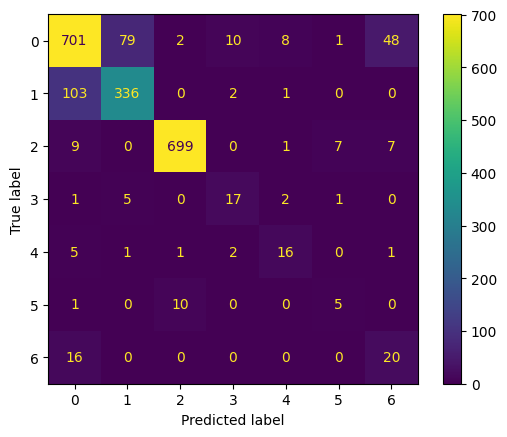

In [1155]:
disp.plot()

In [1156]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.84      0.83      0.83       849
           1       0.80      0.76      0.78       442
           2       0.98      0.97      0.97       723
           3       0.55      0.65      0.60        26
           4       0.57      0.62      0.59        26
           5       0.36      0.31      0.33        16
           6       0.26      0.56      0.36        36

    accuracy                           0.85      2118
   macro avg       0.62      0.67      0.64      2118
weighted avg       0.86      0.85      0.85      2118



In [1157]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
# Calculate accuracy for each class
class_accuracies = {}
for cls in np.unique(classes_x):
    class_mask = (y_validation_inverse == cls)
    class_accuracies[f"Class {cls}"] = accuracy_score(y_validation_inverse[class_mask], classes_x[class_mask])

# Print class-wise accuracies
print("Accuracy for each class:")
for cls, acc in class_accuracies.items():
    print(f"{cls}: {acc:.2f}")

Accuracy for each class:
Class 0: 0.83
Class 1: 0.76
Class 2: 0.97
Class 3: 0.65
Class 4: 0.62
Class 5: 0.31
Class 6: 0.56


In [1158]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Example function to calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, class_names=None):
    """
    Calculate accuracy for each class.
    
    Parameters:
    - y_true: Ground truth labels (list or numpy array).
    - y_pred: Predicted labels (list or numpy array).
    - class_names: List of class names (optional).
    
    Returns:
    - A dictionary with class-wise accuracies.
    """
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate accuracy for each class
    per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
    
    # Organize results
    results = {}
    if class_names is None:
        class_names = [f'Class {i}' for i in range(len(per_class_accuracy))]
    for class_name, accuracy in zip(class_names, per_class_accuracy):
        results[class_name] = accuracy
    
    return results

# Example usage
if __name__ == "__main__":
    # Example true and predicted labels
    #y_true = [0, 1, 2, 2, 0, 1, 1, 0, 2, 1]  # Ground truth
    #y_pred = [0, 1, 1, 2, 0, 1, 2, 0, 2, 1]  # Predictions
    
    # Class names (optional)
    class_names = [0, 1, 2,3,4,5,6]
    
    # Calculate and display per-class accuracy
    accuracy_per_class = calculate_per_class_accuracy(y_validation_inverse, classes_x, class_names)
    for class_name, accuracy in accuracy_per_class.items():
        print(f"{class_name}: {accuracy:.2f}")
    
    # Display class


0: 0.83
1: 0.76
2: 0.97
3: 0.65
4: 0.62
5: 0.31
6: 0.56


In [1159]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.84      0.83      0.83       849
           1       0.80      0.76      0.78       442
           2       0.98      0.97      0.97       723
           3       0.55      0.65      0.60        26
           4       0.57      0.62      0.59        26
           5       0.36      0.31      0.33        16
           6       0.26      0.56      0.36        36

    accuracy                           0.85      2118
   macro avg       0.62      0.67      0.64      2118
weighted avg       0.86      0.85      0.85      2118



In [1160]:
print(segments_test)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)